<a href="https://colab.research.google.com/github/Lerreto/Inpainting-Numerical-Project-2026/blob/juan/impaiting_juan_guardado_automatico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Image Inpainting Restoration Problem**

Image inpainting is an inverse problem in which an observed image $\mathbf{y}$ contains missing pixels from a clean image $\mathbf{x}$:

$$
\mathbf{y}=\mathbf{m}\odot\mathbf{x},
$$

where $\mathbf{m}\in\{0,1\}^{H\times W}$ is a binary mask and $\odot$ denotes element-wise multiplication. In this baseline, each pixel is retained with probability $0.8$; therefore approximately $20\%$ of the spatial samples are removed. Training masks are resampled online, while validation/test masks are deterministic per image.

### **Objective**
Develop a deep-learning model that estimates $\hat{\mathbf{x}}=f_\theta(\mathbf{y})$ from corrupted observations with missing pixels.

### **Experimental protocol**
- Dataset: BSDS500, matching the other image-restoration projects.
- Training crops: $96\times96$ with random crop and horizontal flip.
- Validation crop: centered $288\times288$.
- Fixed corruption level: pixel retention probability $p=0.8$ (approximately $20\%$ missing samples).
- Training masks are resampled online; validation/test masks are deterministic per image.
- Backbone: same compact residual CNN family used in the other projects.
- Loss: MSE by default.
- Metrics: PSNR and SSIM.
- Validation uses inference mode and the best validation checkpoint is restored.
- The corrupted input itself is reported as a baseline.

### **Activities**
1. Improve the baseline performance by changing optimization, loss, capacity, augmentation, or architecture.
2. Compare the restored result against the corrupted-input baseline.
3. Document quantitative and visual results in an academic report.


# **Improvement Difficulty Levels**

To improve the baseline model, use the following difficulty guide.

## **Fixed components (cannot be changed)**
- **Dataset:** keep the BSDS500 dataset exactly as provided.
- **Corruption process:** keep the provided inpainting corruption process fixed. Do not remove it, replace it, or redesign it.

## **Allowed modifications**
You may improve the model by modifying the training pipeline and/or the neural network, for example:
- hyperparameter tuning
- preprocessing choices
- optimizer and learning-rate strategy
- loss function
- regularization
- weight initialization
- neural network architecture

## **Level 1 — Easy**
Focus on **hyperparameter tuning**. Examples:
- change batch size
- change the number of epochs
- change the learning rate
- change the number of filters
- change the number of residual blocks

## **Level 2 — Medium**
Modify the **training recipe** while keeping the general baseline architecture. Examples:
- compare optimizers (Adam, AdamW, RMSprop, etc.)
- test different losses (MSE, MAE/L1, weighted combinations)
- add regularization such as weight decay or dropout if justified
- improve preprocessing or data augmentation
- test learning-rate scheduling

## **Level 3 — Hard**
Modify the **neural network architecture**. Examples:
- deepen the network
- widen the network
- redesign the residual blocks
- add skip connections
- build a different CNN restoration architecture for the same task

## **Recommendation**
Start with a Level 1 improvement, verify whether PSNR/SSIM improve, and then move to Level 2 or Level 3 if needed. For every modification, explain **what changed**, **why it may help**, and **how the metrics and restored images changed**.


In [ ]:
#@title Import libraries and set reproducibility
!pip -q install torchmetrics

import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.optim import SGD, Adam, RMSprop
from torchmetrics.functional.image import peak_signal_noise_ratio
from torchmetrics.functional.image import structural_similarity_index_measure
from torch.optim.lr_scheduler import CosineAnnealingLR
import torch.optim as optim

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cuda:0


In [ ]:
#@title Download BSDS500 Training and Validation Dataset
# Same dataset source used by the original Super-Resolution and Inpainting notebooks.
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC" -O BSDS500.zip && rm -rf /tmp/cookies.txt
!mkdir -p /content/BSDS500
!unzip -q -o BSDS500.zip -d /content/BSDS500

print('Dataset folders:', os.listdir('/content/BSDS500'))


--2026-10-27 04:18:07--  https://docs.google.com/uc?export=download&confirm=&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC
Resolving docs.google.com (docs.google.com)... 192.179.26.102, 192.179.26.139, 192.179.26.113, ...
Connecting to docs.google.com (docs.google.com)|192.179.26.102|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC&export=download [following]
--2026-10-27 04:18:07--  https://drive.usercontent.google.com/download?id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 142.250.99.132, 2607:f8b0:400e:c05::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|142.250.99.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22232532 (21M) [application/octet-stream]
Saving to: ‘BSDS500.zip’

BSDS500.zip         100%[===================>]  21.20M  --.-KB/

In [ ]:
#@title Utility functions
class AverageMeter:
    def __init__(self):
        self.reset()

    def reset(self):
        self.avg = 0.0
        self.sum = 0.0
        self.count = 0

    def update(self, val, n=1):
        self.sum += float(val) * n
        self.count += n
        self.avg = self.sum / max(self.count, 1)


def read_rgb_file(filename):
    return Image.open(filename).convert('RGB')


def compute_metrics(pred, target):
    # Metrics are evaluated in the physical image range [0, 1].
    pred = pred.clamp(0.0, 1.0)
    target = target.clamp(0.0, 1.0)
    psnr = peak_signal_noise_ratio(pred, target, data_range=1.0)
    ssim = structural_similarity_index_measure(pred, target, data_range=1.0)
    return psnr.item(), ssim.item()


def show_tensor(img, ax=None, title=None):
    img = img.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy()
    if ax is None:
        plt.imshow(img)
        plt.axis('off')
        if title:
            plt.title(title)
    else:
        ax.imshow(img)
        ax.axis('off')
        if title:
            ax.set_title(title)


In [ ]:
#@title Random-mask corruption (fixed inverse problem)
class CorruptionProcess:
    def __init__(self, keep_probability=0.8, train=False, seed=1234):
        self.keep_probability = float(keep_probability)
        self.train = train
        self.seed = int(seed)
        if not (0.0 < self.keep_probability <= 1.0):
            raise ValueError('keep_probability must be in (0, 1]')

    def __call__(self, x, idx=None):
        # x: (C, H, W), CPU tensor in [0,1]
        h, w = x.shape[-2:]
        if self.train:
            random_map = torch.rand((1, h, w), dtype=x.dtype)
        else:
            # Deterministic validation/test mask for reproducible metrics.
            g = torch.Generator().manual_seed(self.seed + int(idx or 0))
            random_map = torch.rand((1, h, w), generator=g, dtype=x.dtype)
        mask = (random_map < self.keep_probability).to(x.dtype)
        return x * mask

KEEP_PROBABILITY = 0.80  # fixed for the baseline experiment


In [ ]:
#@title Dataset loader
class PairedRestorationDataset(Dataset):
    def __init__(self, data_path, transform, corruption):
        self.data_path = data_path
        self.imgs_names = sorted([
            f for f in os.listdir(data_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        self.transform = transform
        self.corruption = corruption

    def __len__(self):
        return len(self.imgs_names)

    def __getitem__(self, idx):
        path = os.path.join(self.data_path, self.imgs_names[idx])
        x = self.transform(read_rgb_file(path))
        y = self.corruption(x, idx)
        return x, y


def load_data(data_path, batch_size=4, train_size=96, val_size=288):
    train_transform = transforms.Compose([
        transforms.RandomCrop(train_size),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
    ])
    eval_transform = transforms.Compose([
        transforms.CenterCrop(val_size),
        transforms.ToTensor(),
    ])

    train_corruption = CorruptionProcess(KEEP_PROBABILITY, train=True, seed=SEED)
    eval_corruption = CorruptionProcess(KEEP_PROBABILITY, train=False, seed=SEED + 10000)

    train_dir = os.path.join(data_path, 'train')
    val_dir = os.path.join(data_path, 'val')
    test_dir = os.path.join(data_path, 'test')

    train_ds = PairedRestorationDataset(train_dir, train_transform, train_corruption)
    val_ds = PairedRestorationDataset(val_dir, eval_transform, eval_corruption)
    test_ds = PairedRestorationDataset(test_dir, eval_transform, eval_corruption) if os.path.isdir(test_dir) else None

    loader_kwargs = dict(num_workers=2, pin_memory=torch.cuda.is_available())
    g = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g, **loader_kwargs)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, **loader_kwargs) if test_ds is not None else None
    return train_loader, val_loader, test_loader


## What did we add in the DNN?

We added skip connections in the forward of the DNN, previously it did skip connections in only the residual block, but we decided to also add it to the whole neural network.

In [ ]:
#@title Deep Neural Network Architecture
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=True)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=True)

    def forward(self, x):
        residual = x
        out = self.relu(self.conv1(x))
        out = self.conv2(out)
        return out + residual


class DeepNeuralNetwork(nn.Module):
    """Same compact restoration backbone used by the inpainting baseline."""
    def __init__(self, num_channels=3, base_filter=16, num_residuals=4):
        super().__init__()
        self.conv1 = nn.Conv2d(
            num_channels, base_filter, kernel_size=3, stride=1,
            padding=1, bias=True, padding_mode='reflect'
        )
        self.relu = nn.ReLU(inplace=True)
        self.residuals = nn.Sequential(*[
            ResidualBlock(base_filter, base_filter)
            for _ in range(num_residuals)
        ])
        self.conv2 = nn.Conv2d(base_filter, num_channels, kernel_size=1, stride=1, padding=0, bias=True)

    def forward(self, x):
        feat = self.relu(self.conv1(x))
        out = self.residuals(feat) + feat
        out = self.conv2(out)
        return out + x

#@title Arquitectura: red residual con mejoras activables (Nivel 3)
# Con todas las opciones en False es la misma red original (DeepNeuralNetwork, 46,899 parámetros).

class SEBlock(nn.Module):
    """Atención por canal (squeeze-and-excitation): reescala cada canal según su importancia."""
    def __init__(self, ch, reduction=4):
        super().__init__()
        hidden = max(ch // reduction, 4)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(ch, hidden, 1), nn.ReLU(inplace=True),
            nn.Conv2d(hidden, ch, 1), nn.Sigmoid(),
        )

    def forward(self, x):
        return x * self.fc(x)


class ResidualBlockPlus(nn.Module):
    """Igual al ResidualBlock original, con dilatación y atención opcionales."""
    def __init__(self, ch, dilation=1, se=False):
        super().__init__()
        self.conv1 = nn.Conv2d(ch, ch, 3, 1, padding=dilation, dilation=dilation, bias=True)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(ch, ch, 3, 1, padding=dilation, dilation=dilation, bias=True)
        self.se = SEBlock(ch) if se else None

    def forward(self, x):
        out = self.conv2(self.relu(self.conv1(x)))
        if self.se is not None:
            out = self.se(out)
        return out + x


class ResNetInpaint(nn.Module):
    """Red residual original + mejoras activables:
    - data_consistency: copia los píxeles conocidos de la entrada y solo predice los huecos.
    - mask_input: agrega la máscara (y != 0) como cuarto canal de entrada.
    - dilated: dilataciones 1, 2, 4 en los bloques (campo receptivo ~91 px en vez de ~43 px).
    - se: atención por canal en cada bloque residual.
    """
    def __init__(self, num_channels=3, base_filter=16, num_residuals=10,
                 data_consistency=False, mask_input=False, dilated=False, se=False):
        super().__init__()
        self.data_consistency, self.mask_input = data_consistency, mask_input
        self.opciones = {'data_consistency': data_consistency, 'mask_input': mask_input,
                         'dilated': dilated, 'se': se}
        in_ch = num_channels + 1 if mask_input else num_channels
        self.conv1 = nn.Conv2d(in_ch, base_filter, kernel_size=3, stride=1,
                               padding=1, bias=True, padding_mode='reflect')
        self.relu = nn.ReLU(inplace=True)
        dilations = [(1, 2, 4)[i % 3] if dilated else 1 for i in range(num_residuals)]
        self.residuals = nn.Sequential(*[ResidualBlockPlus(base_filter, d, se) for d in dilations])
        self.conv2 = nn.Conv2d(base_filter, num_channels, kernel_size=1, stride=1, padding=0, bias=True)

    def forward(self, y):
        mask = None
        if self.mask_input or self.data_consistency:
            mask = (y.sum(dim=1, keepdim=True) != 0).float()  # 1 = píxel conocido, 0 = hueco
        inp = torch.cat([y, mask], dim=1) if self.mask_input else y
        feat = self.relu(self.conv1(inp))
        out = self.residuals(feat) + feat
        out = self.conv2(out) + y
        if self.data_consistency:
            out = y * mask + out * (1 - mask)
        return out



#@title Arquitectura: FRRN pequeña (Full-Resolution Residual Network)


class FRRU(nn.Module):
    """Unidad FRRN: une la corriente de pooling (contexto) con la residual (resolución completa)."""
    def __init__(self, pool_in, pool_out, res_ch, scale):
        super().__init__()
        self.scale = scale
        self.conv1 = nn.Conv2d(pool_in + res_ch, pool_out, 3, 1, 1)
        self.conv2 = nn.Conv2d(pool_out, pool_out, 3, 1, 1)
        self.to_res = nn.Conv2d(pool_out, res_ch, 1)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, z, p):
        zp = F.max_pool2d(z, self.scale)                       # residual reducida a la escala del pooling
        p = self.relu(self.conv1(torch.cat([p, zp], dim=1)))
        p = self.relu(self.conv2(p))
        z = z + F.interpolate(self.to_res(p), scale_factor=self.scale,
                              mode='bilinear', align_corners=False)  # corrección a resolución completa
        return z, p


class FRRNLite(nn.Module):
    """Tu red residual original + una corriente de contexto.
    max_scale=8  -> escalas 1/2, 1/4, 1/8 y vuelta (5 FRRU, como la versión anterior).
    max_scale=16 -> escalas 1/2, 1/4, 1/8, 1/16 y vuelta (7 FRRU).
    Los bloques residuales se reparten mitad antes y mitad después de las FRRU."""
    def __init__(self, num_channels=3, base_filter=16, num_residuals=10,
                 data_consistency=False, max_scale=8):
        super().__init__()
        if max_scale < 4 or max_scale & (max_scale - 1):
            raise ValueError('max_scale debe ser una potencia de 2 mayor o igual a 4 (4, 8, 16...)')
        C = base_filter
        self.data_consistency, self.max_scale = data_consistency, max_scale
        self.conv1 = nn.Conv2d(num_channels, C, 3, 1, 1, bias=True, padding_mode='reflect')
        self.relu = nn.ReLU(inplace=True)
        n_pre = num_residuals // 2
        self.pre = nn.Sequential(*[ResidualBlock(C, C) for _ in range(n_pre)])
        self.post = nn.Sequential(*[ResidualBlock(C, C) for _ in range(num_residuals - n_pre)])
        # Escalas: baja 2 -> 4 -> ... -> max_scale y vuelve ... -> 4 -> 2
        enc = [2 ** i for i in range(1, max_scale.bit_length())]
        self.scales = enc + enc[-2::-1]
        cfg, prev_w = [], C
        for s in self.scales:
            w = C if s == 2 else 2 * C                         # canales de la corriente de pooling
            cfg.append((prev_w, w, s))
            prev_w = w
        self.frrus = nn.ModuleList([FRRU(pi, po, C, s) for pi, po, s in cfg])
        self.conv2 = nn.Conv2d(C, num_channels, 1, 1, 0, bias=True)

    def forward(self, y):
        H, W = y.shape[-2:]
        m = self.max_scale
        ph, pw = (-H) % m, (-W) % m                            # el tamaño debe ser múltiplo de max_scale
        x = F.pad(y, (0, pw, 0, ph), mode='reflect') if (ph or pw) else y
        feat = self.relu(self.conv1(x))
        z = self.pre(feat)
        p = F.max_pool2d(z, 2)
        prev = 2
        for frru, s in zip(self.frrus, self.scales):
            if s > prev:
                p = F.max_pool2d(p, s // prev)
            elif s < prev:
                p = F.interpolate(p, scale_factor=prev // s, mode='bilinear', align_corners=False)
            prev = s
            z, p = frru(z, p)
        z = self.post(z) + feat
        out = self.conv2(z)[..., :H, :W] + y
        if self.data_consistency:
            mask = (y.sum(dim=1, keepdim=True) != 0).float()   # 1 = píxel conocido, 0 = hueco
            out = y * mask + out * (1 - mask)
        return out

Codigo de prueba si me funciona esta monda

In [ ]:
# Prueba rápida de FRRNLite
for dc in (False, True):
    m = FRRNLite(base_filter=16, num_residuals=10, data_consistency=dc).to(device)
    print('data_consistency =', dc, '| params:', f"{sum(p.numel() for p in m.parameters()):,}")
    for s in (96, 288, 100):
        x = torch.rand(2, 3, s, s, device=device)
        mask = (torch.rand(2, 1, s, s, device=device) < 0.8).float()
        y = x * mask
        out = m(y)
        conocidos = (out - y).mul(mask).abs().max().item()
        print('  ', s, '->', tuple(out.shape), '| NaN:', torch.isnan(out).any().item(),
              '| error en conocidos:', round(conocidos, 6))
x = torch.rand(4, 3, 96, 96, device=device)
y = x * (torch.rand(4, 1, 96, 96, device=device) < 0.8).float()
nn.L1Loss()(m(y), x).backward()
print('sin gradiente:', [n for n, p in m.named_parameters() if p.grad is None])

data_consistency = False | params: 129,923
   96 -> (2, 3, 96, 96) | NaN: False | error en conocidos: 1.024692
   288 -> (2, 3, 288, 288) | NaN: False | error en conocidos: 1.079911
   100 -> (2, 3, 100, 100) | NaN: False | error en conocidos: 1.072162
data_consistency = True | params: 129,923
   96 -> (2, 3, 96, 96) | NaN: False | error en conocidos: 0.0
   288 -> (2, 3, 288, 288) | NaN: False | error en conocidos: 0.0
   100 -> (2, 3, 100, 100) | NaN: False | error en conocidos: 0.0
sin gradiente: []


## What did we add?

For testing purposes, we added the AdamW (Adam with weight decay) optimizer and the RMSE cost function (Root Mean Square Error).

We added early stopping, with a new variable called 'patiente', this variable's purpose is to stop the training if the model can't find a better val_loss in a number of epochs determined by the variable, this allows to increase the number of epochs but allow it to stop whenever the val_loss converges.

We also changed the weight decay of the optimizers to 1e-6, since the previous value (1e-9) was too low for most optimizers, especially Adam and AdamW.

## Why didn't we stick with only modifying the hyperparameters?

Although by only modifying the hyperparameters we were able to get really good results, we weren't satisfied, we had two main reasons to do this:

* Getting good results required increasing the hyperparameters, however, by doing this, the computational costs increased exponentially, which in real life usage could result in a downside.
* We didn't like the idea of sticking to only changing hyperparameters, we knew we could achieve better results by changing the way the training worked (and, if needed, changing the CNN architecture), this as a side effect would allow to not having to increase the computational cost of the DNN to have better results.

## Explicacion del Deep Neural Network Architecture

Se podria decir que este es nuestro ultimo paso, realmente obtuvimos buenos resultados anteriormente sin haber llegado a esta parte en concreto, pero decidimos, tanto por tema de avaricia como tema de cumplimiento del reto, modificarlo para tener mejores resultados si era posible.

Deep Neural Network Architecture = Es la estructura u organizacion interna de un modelo de aprendizaje profundo. Define como se disponen las neuronas articiales en capas, como se interconectan entre si y de que manera fluye la informacion desde los datos de entrada hasta la prediccion final

Tenemos 3 en total, la basica que venia por default, y 2 que decidi añadir, fueron sacadas de un paper que hablaba en concreto de la FNNR, de la cual decidi probar primero la del estado de arte la ResNetInapint.

**DeepNeuralNetwork:** Procesa a ciegas y solo a nivel local. No sabe dónde están los huecos ni respeta la imagen original; simplemente aplica filtros en un área pequeña (~43 px) y le suma el resultado a la entrada.

**ResNetInpaint:** Sabe dónde está el daño y solo arregla el hueco. Lee la máscara para ubicar la falla, busca contexto en zonas lejanas y reemplaza únicamente los píxeles dañados, dejando los píxeles originales 100% intactos.

**FRRNLite:** Mira la imagen completa para deducir huecos grandes. Procesa la imagen a resolución completa (para detalles) y en miniatura (para entender la escena global) al mismo tiempo, combinando ambas perspectivas. Aparte, la llamamos lite porque la original opera en 1/32, esta esta a 1/8 xd.

Esto de agroso modo, de tal manera que pasamos de mirar el contexto en general, de restaurar todo porque si, con la DeepNeuralNetwork hacemos recorrido de todo, nos enfocamos en concreto en los huecos, y de ahi resolvemos, dandonos eficiencia de computo, y mayor detalle.

In [ ]:
#@title Model hyperparameters, optimizer, and loss
EPOCHS = 300 #@param
BATCH_SIZE = 4 #@param

patience = 30 #@param
base_filter = 16 #@param
num_residuals = 10 #@param

# ---- Selector de modelo ----
model_name = 'FRRNLite' #@param ["DeepNeuralNetwork", "ResNetInpaint", "FRRNLite"] {type:"string"}

frrn_max_scale = 16  #@param [8, 16] {type:"raw"}

# Opciones de ResNetInpaint (se ignoran en los otros modelos)
data_consistency = True  #@param {type:"boolean"}
mask_input = False  #@param {type:"boolean"}
dilated = False  #@param {type:"boolean"}
se_attention = False  #@param {type:"boolean"}

if model_name == 'DeepNeuralNetwork':
    model = DeepNeuralNetwork(base_filter=base_filter, num_residuals=num_residuals)
    model_config = {'nombre': model_name, 'base_filter': base_filter, 'num_residuals': num_residuals}
elif model_name == 'ResNetInpaint':
    model = ResNetInpaint(base_filter=base_filter, num_residuals=num_residuals,
                          data_consistency=data_consistency, mask_input=mask_input,
                          dilated=dilated, se=se_attention)
    model_config = {'nombre': model_name, 'base_filter': base_filter, 'num_residuals': num_residuals,
                    'data_consistency': data_consistency, 'mask_input': mask_input,
                    'dilated': dilated, 'se_attention': se_attention}
elif model_name == 'FRRNLite':
    model = FRRNLite(base_filter=base_filter, num_residuals=num_residuals,
                     data_consistency=data_consistency, max_scale=frrn_max_scale)
    model_config = {'nombre': model_name, 'base_filter': base_filter,
                    'num_residuals': num_residuals, 'data_consistency': data_consistency,
                    'max_scale': frrn_max_scale}
else:
    raise ValueError('Unknown model')
model = model.to(device)
print('Modelo:', model_config)

optimizer_name = 'AdamW' #@param ["SGD", "Adam", "RMSprop", "AdamW"] {type:"string"}
cost_function = 'MAE' #@param ["MSE", "MAE", "RMSE"] {type:"string"}
learning_rate = 2e-3 #@param

if optimizer_name == 'SGD':
    optimizer = SGD(model.parameters(), lr=learning_rate, momentum=0.9, weight_decay=1e-6)
elif optimizer_name == 'Adam':
    optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=1e-6)
elif optimizer_name == 'RMSprop':
    optimizer = RMSprop(model.parameters(), lr=learning_rate, weight_decay=1e-6)
elif optimizer_name == 'AdamW':
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-6)
else:
    raise ValueError('Unknown optimizer')


if cost_function == 'MSE' or cost_function == 'RMSE':
  criterion = nn.MSELoss()
elif cost_function == 'MAE':
  criterion = nn.L1Loss()
else:
  raise ValueError('Unknown cost function')

scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {n_params:,}')

CHECKPOINT_PATH = "/content/best_inpainting_model.pt"
print(f"Optimizer: {optimizer_name}")
print(f"Cost function: {cost_function}")


Modelo: {'nombre': 'FRRNLite', 'base_filter': 16, 'num_residuals': 10, 'data_consistency': True, 'max_scale': 16}
Trainable parameters: 177,187
Optimizer: AdamW
Cost function: MAE


con la frrn_max_scale me dice cuantas veces se aleja la red de la imagen para mirar el contexto, la red mira en general, pero para esta aplicacion, no es tan necesario tener un numero tan grande

conclusion = da igual

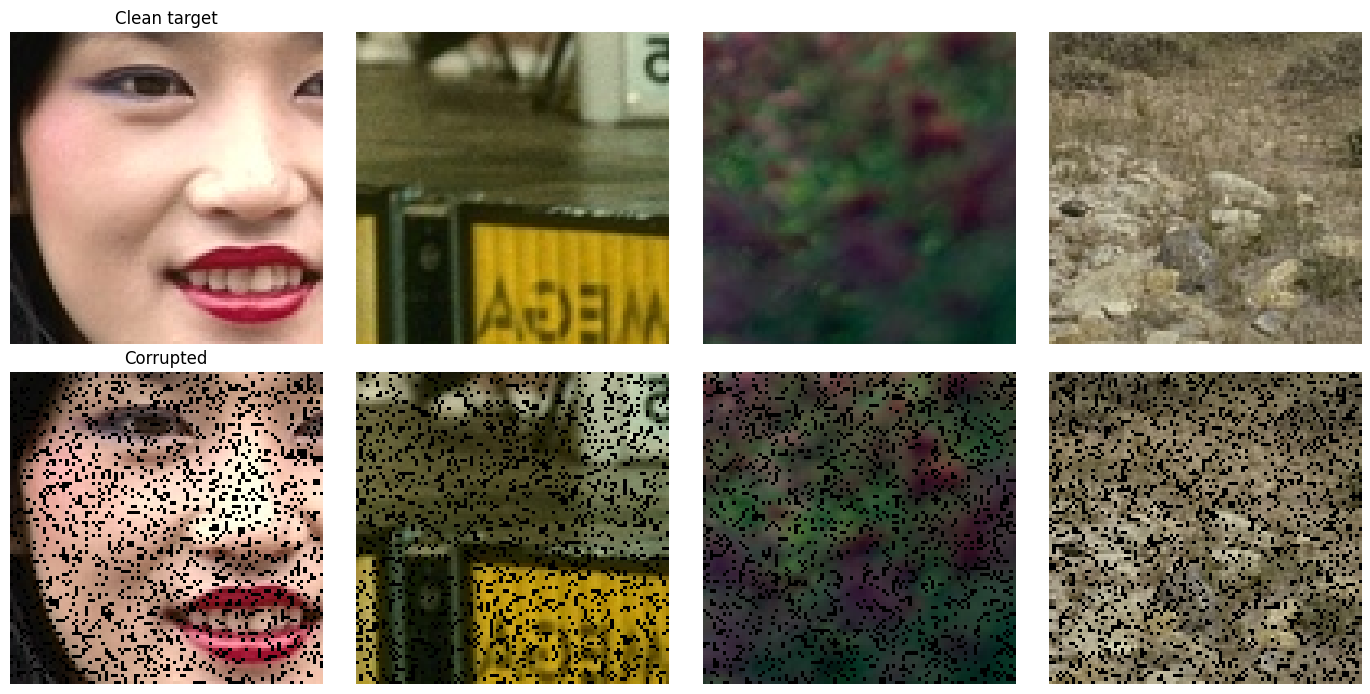

Pixel retention probability: 0.80 | Missing samples: 20%
Train batches: 50 | Validation images: 100
Independent test set: not available in this dataset package


In [ ]:
#@title Load dataset and visualize samples
data_path = '/content/BSDS500'
train_loader, val_loader, test_loader = load_data(data_path, batch_size=BATCH_SIZE)

x, y = next(iter(train_loader))
num_imgs = min(4, x.size(0))
fig, axs = plt.subplots(2, num_imgs, figsize=(14, 7))
for i in range(num_imgs):
    show_tensor(x[i], axs[0, i], 'Clean target' if i == 0 else None)
    show_tensor(y[i], axs[1, i], 'Corrupted' if i == 0 else None)
plt.tight_layout()
plt.show()

print(f'Pixel retention probability: {KEEP_PROBABILITY:.2f} | Missing samples: {(1-KEEP_PROBABILITY)*100:.0f}%')
print('Train batches:', len(train_loader), '| Validation images:', len(val_loader))
print('Independent test set:', 'available' if test_loader is not None else 'not available in this dataset package')


In [ ]:
#@title Baseline vs restored-image evaluation
def evaluate(loader, model=None):
    loss_m, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

    if model is not None:
        model.eval()

    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            pred = y if model is None else model(y)
            if cost_function == 'RMSE':
              loss = torch.sqrt(criterion(pred,x))
            else:
              loss = criterion(pred, x)
            psnr_val, ssim_val = compute_metrics(pred, x)

            n = x.size(0)
            loss_m.update(loss.item(), n)
            psnr_m.update(psnr_val, n)
            ssim_m.update(ssim_val, n)

    return {'loss': loss_m.avg, 'psnr': psnr_m.avg, 'ssim': ssim_m.avg}

# Baseline before training (validation)
baseline_pre = evaluate(val_loader, model=None)
print(f"Corrupted-input validation baseline | PSNR {baseline_pre['psnr']:.2f} dB | SSIM {baseline_pre['ssim']:.3f}")


Corrupted-input validation baseline | PSNR 13.54 dB | SSIM 0.278


In [ ]:
#@title Training process with validation and best-model checkpoint
count = 0
history = {
    'train_loss': [], 'train_psnr': [], 'train_ssim': [],
    'val_loss': [], 'val_psnr': [], 'val_ssim': []
}

best_val_psnr = -float('inf')
best_state = None

for epoch in range(EPOCHS):
    count+=1

    if count<patience:
      losses, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()
      val_losses, val_psnr_m, val_ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

      model.train()
      for x, y in train_loader:
          x = x.to(device, non_blocking=True)
          y = y.to(device, non_blocking=True)

          optimizer.zero_grad(set_to_none=True)
          x_hat = model(y)
          loss = criterion(x_hat, x)
          loss.backward()
          optimizer.step()

          with torch.no_grad():
              psnr_val, ssim_val = compute_metrics(x_hat, x)

          n = x.size(0)
          losses.update(loss.item(), n)
          psnr_m.update(psnr_val, n)
          ssim_m.update(ssim_val, n)

      model.eval()
      with torch.inference_mode():
          for x, y in val_loader:
              x = x.to(device, non_blocking=True)
              y = y.to(device, non_blocking=True)
              x_hat = model(y)

              loss = criterion(x_hat, x)
              psnr_val, ssim_val = compute_metrics(x_hat, x)

              n = x.size(0)
              val_losses.update(loss.item(), n)
              val_psnr_m.update(psnr_val, n)
              val_ssim_m.update(ssim_val, n)

      history['train_loss'].append(losses.avg)
      history['train_psnr'].append(psnr_m.avg)
      history['train_ssim'].append(ssim_m.avg)
      history['val_loss'].append(val_losses.avg)
      history['val_psnr'].append(val_psnr_m.avg)
      history['val_ssim'].append(val_ssim_m.avg)

      scheduler.step()

      if val_psnr_m.avg > best_val_psnr:
          count=0
          best_val_psnr = val_psnr_m.avg
          best_state = copy.deepcopy(model.state_dict())
          torch.save(best_state, CHECKPOINT_PATH)
          print(
          f'New best PSNR at Epoch {epoch+1:03d}/{EPOCHS} | '
          f'Loss {losses.avg:.7f} | PSNR {psnr_m.avg:.2f} | SSIM {ssim_m.avg:.3f} | '
          f'Val Loss {val_losses.avg:.7f} | Val PSNR {val_psnr_m.avg:.2f} | Val SSIM {val_ssim_m.avg:.3f}'
          )
    else:
      print(f"There wasn't a better value after {count} epochs, stopping training")
      break

model.load_state_dict(best_state)
print(f'Best validation PSNR: {best_val_psnr:.2f} dB')
print('Best checkpoint:', CHECKPOINT_PATH)


New best PSNR at Epoch 001/300 | Loss 0.0257148 | PSNR 23.48 | SSIM 0.631 | Val Loss 0.0152641 | Val PSNR 27.32 | Val SSIM 0.793
New best PSNR at Epoch 002/300 | Loss 0.0141225 | PSNR 27.56 | SSIM 0.801 | Val Loss 0.0123375 | Val PSNR 28.80 | Val SSIM 0.852
New best PSNR at Epoch 003/300 | Loss 0.0117508 | PSNR 28.96 | SSIM 0.849 | Val Loss 0.0100336 | Val PSNR 30.34 | Val SSIM 0.898
New best PSNR at Epoch 004/300 | Loss 0.0094870 | PSNR 30.52 | SSIM 0.890 | Val Loss 0.0091598 | Val PSNR 31.14 | Val SSIM 0.915
New best PSNR at Epoch 005/300 | Loss 0.0085777 | PSNR 31.30 | SSIM 0.908 | Val Loss 0.0079797 | Val PSNR 32.13 | Val SSIM 0.933
New best PSNR at Epoch 006/300 | Loss 0.0086270 | PSNR 31.36 | SSIM 0.907 | Val Loss 0.0080785 | Val PSNR 32.19 | Val SSIM 0.928
New best PSNR at Epoch 007/300 | Loss 0.0075172 | PSNR 32.32 | SSIM 0.926 | Val Loss 0.0076490 | Val PSNR 32.52 | Val SSIM 0.933
New best PSNR at Epoch 008/300 | Loss 0.0077057 | PSNR 32.15 | SSIM 0.927 | Val Loss 0.0071944 | 

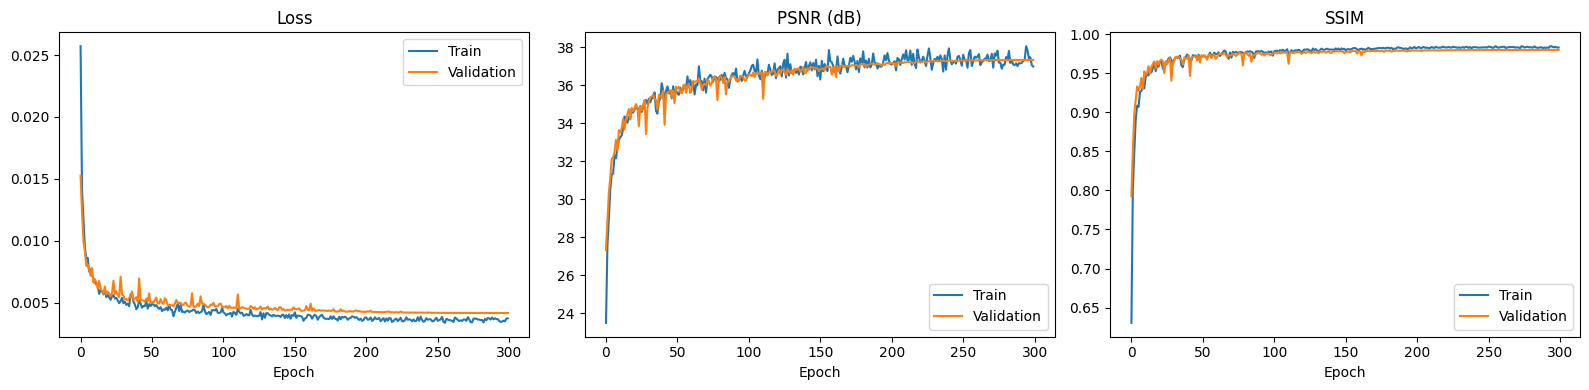

In [ ]:
#@title Training curves
fig, axs = plt.subplots(1, 3, figsize=(16, 4))

axs[0].plot(history['train_loss'], label='Train')
axs[0].plot(history['val_loss'], label='Validation')
axs[0].set_title('Loss')
axs[0].set_xlabel('Epoch')
axs[0].legend()

axs[1].plot(history['train_psnr'], label='Train')
axs[1].plot(history['val_psnr'], label='Validation')
axs[1].set_title('PSNR (dB)')
axs[1].set_xlabel('Epoch')
axs[1].legend()

axs[2].plot(history['train_ssim'], label='Train')
axs[2].plot(history['val_ssim'], label='Validation')
axs[2].set_title('SSIM')
axs[2].set_xlabel('Epoch')
axs[2].legend()

plt.tight_layout()
plt.show()


In [ ]:
#@title Baseline vs restored-image evaluation
def evaluate(loader, model=None):
    loss_m, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

    if model is not None:
        model.eval()

    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            pred = y if model is None else model(y)
            loss = criterion(pred, x)
            psnr_val, ssim_val = compute_metrics(pred, x)

            n = x.size(0)
            loss_m.update(loss.item(), n)
            psnr_m.update(psnr_val, n)
            ssim_m.update(ssim_val, n)

    return {'loss': loss_m.avg, 'psnr': psnr_m.avg, 'ssim': ssim_m.avg}

final_loader = test_loader if test_loader is not None else val_loader
final_split = 'TEST' if test_loader is not None else 'VALIDATION (no independent test folder found)'

baseline = evaluate(final_loader, model=None)
restored = evaluate(final_loader, model=model)

print(final_split)
print(f"Input baseline  | Loss {baseline['loss']:.7f} | PSNR {baseline['psnr']:.2f} dB | SSIM {baseline['ssim']:.3f}")
print(f"Restored model  | Loss {restored['loss']:.7f} | PSNR {restored['psnr']:.2f} dB | SSIM {restored['ssim']:.3f}")
print(f"PSNR gain       | {restored['psnr'] - baseline['psnr']:+.2f} dB")


VALIDATION (no independent test folder found)
Input baseline  | Loss 0.0851477 | PSNR 13.54 dB | SSIM 0.278
Restored model  | Loss 0.0041756 | PSNR 37.34 dB | SSIM 0.980
PSNR gain       | +23.81 dB


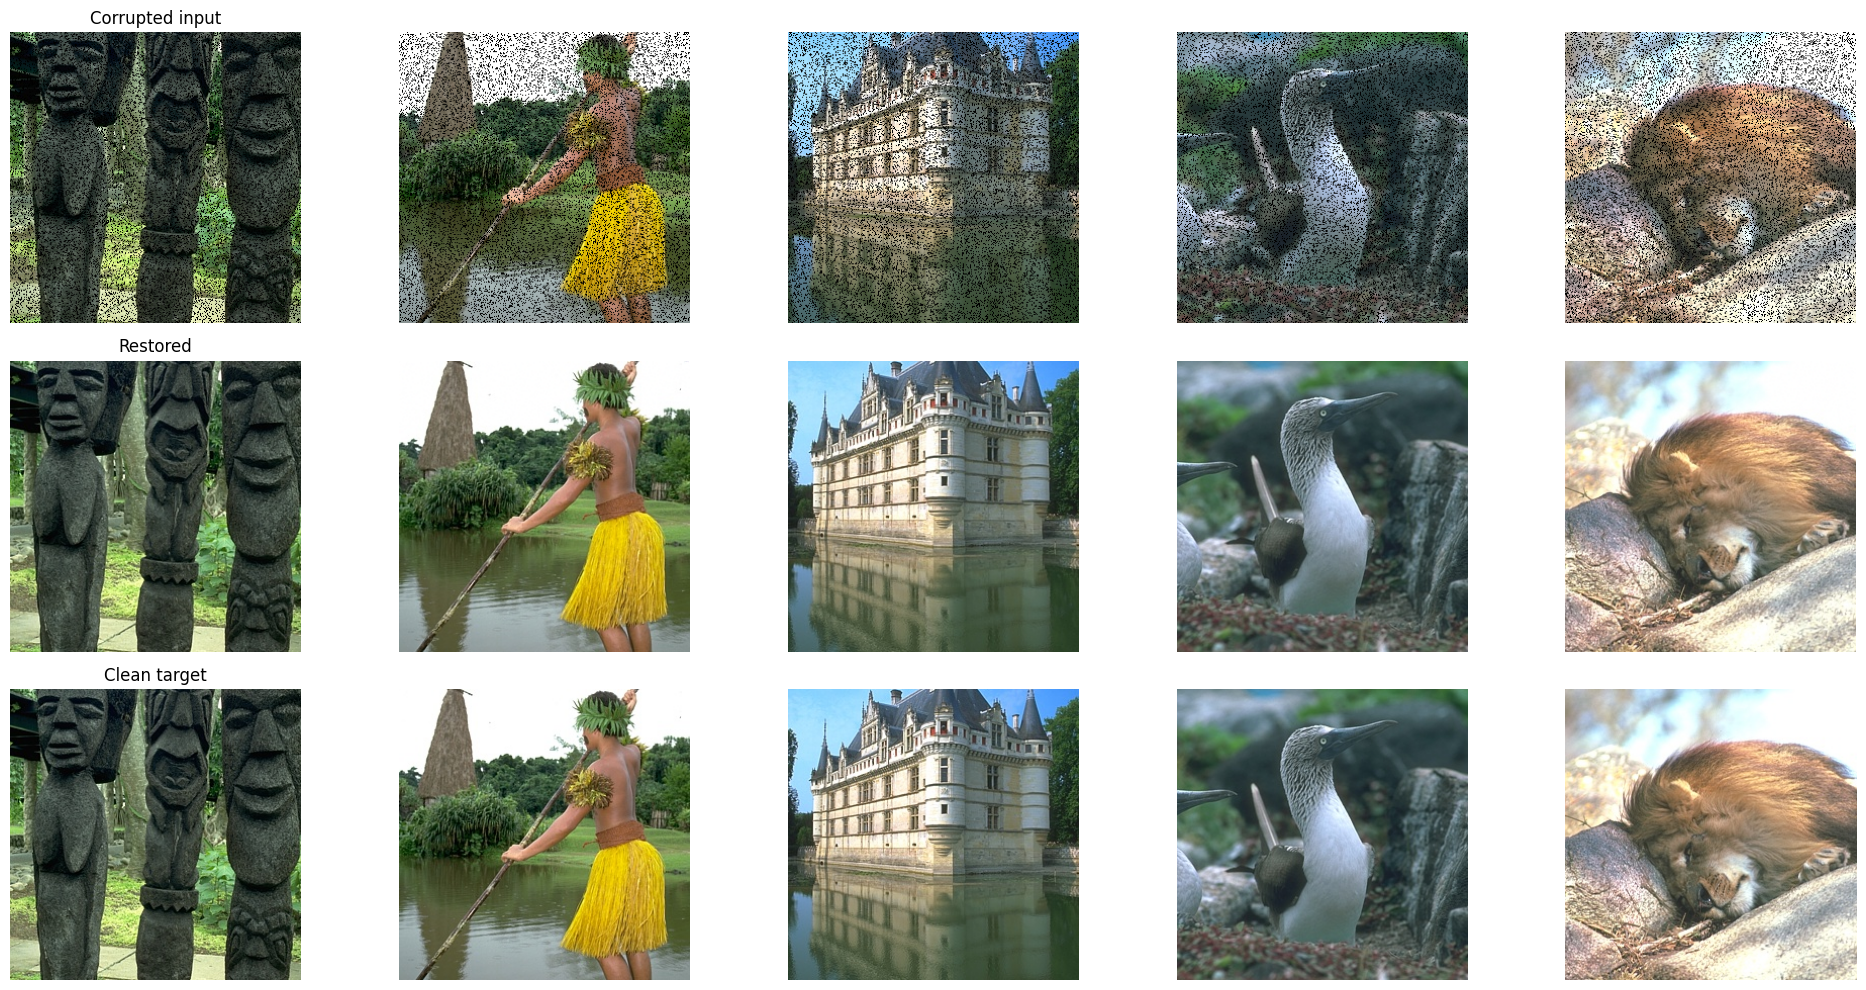

In [ ]:
#@title Visual inference
loader = test_loader if test_loader is not None else val_loader
num_images = min(5, len(loader))
fig, axs = plt.subplots(3, num_images, figsize=(4*num_images, 10))
axs = np.array(axs).reshape(3, num_images)

model.eval()
with torch.inference_mode():
    for i, (x, y) in enumerate(loader):
        if i >= num_images:
            break
        pred = model(y.to(device)).cpu().clamp(0, 1)
        show_tensor(y[0], axs[0, i], 'Corrupted input' if i == 0 else None)
        show_tensor(pred[0], axs[1, i], 'Restored' if i == 0 else None)
        show_tensor(x[0], axs[2, i], 'Clean target' if i == 0 else None)

plt.tight_layout()
plt.show()


En lo siguiente va a haber una seccion de auto guardado y carga de los datos que vayamos recolentando de cada corrida, guardando los hiperparametros al igual que sus respectivos resultados y graficas. Esto lo hacemos con el fin de tener un seguimiento constante, un historial del avance del proyecto, todo guardado en un drive. Pedro, fue hecho con IA para que se viera mas bonito esto, no me juzges UnU

# Codigo de guardado

In [ ]:
#@title Guardar resultados en Google Drive (con descripción y botón)
import csv, html, json, os, shutil
from datetime import datetime, timezone, timedelta
import numpy as np
from matplotlib.figure import Figure
import ipywidgets as widgets
from IPython.display import display
from google.colab import drive

try:
    from zoneinfo import ZoneInfo
    BOGOTA = ZoneInfo('America/Bogota')
except Exception:
    BOGOTA = timezone(timedelta(hours=-5))  # Colombia no usa horario de verano

drive.mount('/content/drive')

# Valores por defecto (se pueden cambiar en los campos de abajo, sin tocar el código)
DEFAULT_NOTEBOOK_NAME = 'impaiting_pedro_marin'
DEFAULT_SOURCE_URL = 'https://github.com/Lerreto/Inpainting-Numerical-Project-2026/blob/pedro/impaiting_pedro_marin.ipynb'
_CANDIDATES = [
    '/content/drive/MyDrive/UIS/Semestre 4/Analisis Numerico/Backs',  # dueño de la carpeta
    '/content/drive/MyDrive/Backs',                                    # compañero con acceso directo
]
DEFAULT_DRIVE_ROOT = next((p for p in _CANDIDATES if os.path.isdir(p)), _CANDIDATES[0])


def guardar_resultados(descripcion, notebook_name, drive_root, source_url):
    notebook_name = notebook_name.strip()
    drive_root = drive_root.strip().rstrip('/')
    if not notebook_name:
        raise ValueError('El nombre del notebook no puede estar vacío.')
    if not drive_root.startswith('/content/drive/'):
        raise ValueError("La ruta debe empezar por '/content/drive/' (por ejemplo '/content/drive/MyDrive/Mi_Carpeta').")
    if not os.path.isdir('/content/drive/MyDrive') and not drive_root.startswith('/content/drive/Shareddrives'):
        raise RuntimeError('Drive no está montado. Ejecuta de nuevo la celda.')

    now = datetime.now(BOGOTA)  # hora de Colombia
    _modelo = globals().get('model_name', type(model).__name__)
    run_name = (f"{now:%Y%m%d_%H%M%S}_{_modelo}_{optimizer_name}_{cost_function}"
                f"_lr{learning_rate}_bf{base_filter}")
    save_dir = os.path.join(drive_root, notebook_name, run_name)
    os.makedirs(save_dir, exist_ok=True)
    print('Guardando en:', save_dir)

    # ---- Historial por época ----
    keys = list(history.keys())
    n_epochs_run = len(history['train_loss'])
    with open(os.path.join(save_dir, 'history.csv'), 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['epoch'] + keys)
        for i in range(n_epochs_run):
            w.writerow([i + 1] + [history[k][i] for k in keys])

    # ---- Mejor época (misma línea que imprime el entrenamiento) ----
    best_idx = int(np.argmax(history['val_psnr']))
    best_line = (
        f"New best PSNR at Epoch {best_idx + 1:03d}/{EPOCHS} | "
        f"Loss {history['train_loss'][best_idx]:.7f} | PSNR {history['train_psnr'][best_idx]:.2f} | "
        f"SSIM {history['train_ssim'][best_idx]:.3f} | "
        f"Val Loss {history['val_loss'][best_idx]:.7f} | "
        f"Val PSNR {history['val_psnr'][best_idx]:.2f} | Val SSIM {history['val_ssim'][best_idx]:.3f}"
    )
    best_summary = f"Best validation PSNR: {best_val_psnr:.2f} dB"

    # ---- Hiperparámetros ----
    hiperparametros = {
        'notebook': notebook_name,
        'fuente': source_url.strip(),
        'descripcion': descripcion.strip(),
        'fecha_corrida': now.isoformat(timespec='seconds'),  # incluye la zona (-05:00)
        'dispositivo': str(device),
        'semilla': SEED,
        'dataset': {'nombre': 'BSDS500', 'recorte_train': 96, 'recorte_val': 288, 'batch_size': BATCH_SIZE},
        'corrupcion': {'prob_retencion': KEEP_PROBABILITY,
                       'fraccion_faltante': round(1 - KEEP_PROBABILITY, 4),
                       'mascaras_train': 'online',
                       'mascaras_eval': 'deterministas'},
        'modelo': {**globals().get('model_config', {'nombre': type(model).__name__}),
                   'parametros_entrenables': n_params},
        'entrenamiento': {'epocas_max': EPOCHS, 'epocas_ejecutadas': n_epochs_run,
                          'patience': patience, 'optimizador': optimizer_name,
                          'learning_rate': learning_rate,
                          'weight_decay': optimizer.param_groups[0]['weight_decay'],
                          'funcion_costo': cost_function,
                          'scheduler': 'CosineAnnealingLR', 'T_max': EPOCHS},
    }
    with open(os.path.join(save_dir, 'hiperparametros.json'), 'w', encoding='utf-8') as f:
        json.dump(hiperparametros, f, indent=2, ensure_ascii=False)

    # ---- Métricas ----
    metricas = {
        'mejor_epoca': best_idx + 1,
        'mejor_val_psnr_db': best_val_psnr,
        'evaluacion_split': final_split,
        'baseline': baseline,
        'restaurado': restored,
        'ganancia_psnr_db': restored['psnr'] - baseline['psnr'],
    }
    with open(os.path.join(save_dir, 'metricas.json'), 'w', encoding='utf-8') as f:
        json.dump(metricas, f, indent=2, ensure_ascii=False)

    resumen = [
        f"Descripción: {descripcion.strip() or '(sin descripción)'}",
        '',
        best_line,
        best_summary,
        '',
        f"Baseline (entrada corrupta) | PSNR {baseline['psnr']:.2f} dB | SSIM {baseline['ssim']:.3f}",
        f"Restaurado                  | PSNR {restored['psnr']:.2f} dB | SSIM {restored['ssim']:.3f}",
        f"Ganancia PSNR               | {restored['psnr'] - baseline['psnr']:+.2f} dB",
        f"Evaluado sobre: {final_split}",
    ]
    with open(os.path.join(save_dir, 'resumen.txt'), 'w', encoding='utf-8') as f:
        f.write('\n'.join(resumen) + '\n')

    # ---- Mejor checkpoint ----
    shutil.copy(CHECKPOINT_PATH, os.path.join(save_dir, 'mejor_modelo.pt'))

    # Las figuras se crean con Figure() (sin pyplot) para que Colab no las muestre en pantalla.

    # ---- Figura 1: curvas de entrenamiento ----
    fig = Figure(figsize=(16, 4))
    axs = fig.subplots(1, 3)
    for ax, m, t in zip(axs, ['loss', 'psnr', 'ssim'], ['Loss', 'PSNR (dB)', 'SSIM']):
        ax.plot(history[f'train_{m}'], label='Train')
        ax.plot(history[f'val_{m}'], label='Validation')
        ax.axvline(best_idx, color='gray', linestyle='--', label='Mejor época')
        ax.set_title(t)
        ax.set_xlabel('Época')
        ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(save_dir, 'fig_curvas_entrenamiento.png'), dpi=150, bbox_inches='tight')

    # ---- Figura 2: comparación de métricas, baseline vs restaurado ----
    labels = ['Entrada corrupta', 'Restaurada']
    fig = Figure(figsize=(10, 4))
    axs = fig.subplots(1, 2)
    bars = axs[0].bar(labels, [baseline['psnr'], restored['psnr']], color=['gray', 'tab:blue'])
    axs[0].bar_label(bars, fmt='%.2f')
    axs[0].set_title('PSNR (dB)')
    bars = axs[1].bar(labels, [baseline['ssim'], restored['ssim']], color=['gray', 'tab:blue'])
    axs[1].bar_label(bars, fmt='%.3f')
    axs[1].set_title('SSIM')
    fig.tight_layout()
    fig.savefig(os.path.join(save_dir, 'fig_comparacion_metricas.png'), dpi=150, bbox_inches='tight')

    # ---- Figura 3: comparación visual (entrada, restaurada, objetivo) ----
    final_loader = test_loader if test_loader is not None else val_loader
    num_show = min(3, len(final_loader))
    fig = Figure(figsize=(4 * num_show, 10))
    axs = fig.subplots(3, num_show, squeeze=False)
    model.eval()
    with torch.inference_mode():
        for i, (x, y) in enumerate(final_loader):
            if i >= num_show:
                break
            pred = model(y.to(device)).cpu().clamp(0, 1)
            show_tensor(y[0], axs[0, i], 'Entrada corrupta' if i == 0 else None)
            show_tensor(pred[0], axs[1, i], 'Restaurada' if i == 0 else None)
            show_tensor(x[0], axs[2, i], 'Objetivo limpio' if i == 0 else None)
    fig.tight_layout()
    fig.savefig(os.path.join(save_dir, 'fig_comparacion_visual.png'), dpi=150, bbox_inches='tight')

    os.sync()  # intenta forzar la escritura antes de terminar
    esperados = ['hiperparametros.json', 'metricas.json', 'resumen.txt', 'history.csv', 'mejor_modelo.pt',
                 'fig_curvas_entrenamiento.png', 'fig_comparacion_metricas.png', 'fig_comparacion_visual.png']
    faltan = [n for n in esperados if not os.path.exists(os.path.join(save_dir, n))]
    if faltan:
        print('ATENCIÓN, faltan archivos:', faltan)
    print('Archivos guardados:', sorted(os.listdir(save_dir)))
    print(best_line)
    print(best_summary)
    return save_dir, now


# ---- Interfaz: campos + botón + mensaje de confirmación ----
_style = {'description_width': '95px'}
_wide = widgets.Layout(width='760px')
w_nb = widgets.Text(value=DEFAULT_NOTEBOOK_NAME, description='Notebook:', style=_style, layout=_wide)
w_root = widgets.Text(value=DEFAULT_DRIVE_ROOT, description='Ruta en Drive:', style=_style, layout=_wide)
w_src = widgets.Text(value=DEFAULT_SOURCE_URL, description='Fuente:', style=_style, layout=_wide)
w_desc = widgets.Textarea(placeholder='Escribe aquí una descripción de esta corrida (opcional)',
                          description='Descripción:', style=_style,
                          layout=widgets.Layout(width='760px', height='90px'))
btn = widgets.Button(description='Guardar en Drive', button_style='success', icon='save')
status = widgets.HTML(value='')
out = widgets.Output()

_BOX = 'padding:8px 12px;border-radius:6px;border:1px solid {c};color:{c};margin:6px 0;max-width:740px'


def _on_click(_):
    out.clear_output()
    btn.disabled = True
    status.value = '<div style="opacity:.8;margin:6px 0">⏳ Guardando…</div>'
    try:
        with out:
            save_dir, ts = guardar_resultados(w_desc.value, w_nb.value, w_root.value, w_src.value)
        status.value = (f'<div style="{_BOX.format(c="#3fb950")}">✅ Guardado a las {ts:%H:%M:%S} '
                        f'(hora Colombia) en <code>{html.escape(save_dir)}</code></div>')
    except Exception as e:
        status.value = (f'<div style="{_BOX.format(c="#f85149")}">❌ Error al guardar: '
                        f'{html.escape(repr(e))}</div>')
    finally:
        btn.disabled = False


def _clear_status(change):
    # Al cambiar cualquier campo desaparece el mensaje de "guardado".
    status.value = ''
    out.clear_output()


for _w in (w_desc, w_nb, w_root, w_src):
    _w.observe(_clear_status, names='value')

btn.on_click(_on_click)
display(widgets.VBox([w_nb, w_root, w_src, w_desc, btn, status, out]))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Codigo de visualizar

In [ ]:
#@title Visualizador de corridas guardadas
import glob, html, json, os
from datetime import datetime, timezone, timedelta
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from google.colab import drive

try:
    from zoneinfo import ZoneInfo
    BOGOTA = ZoneInfo('America/Bogota')
except Exception:
    BOGOTA = timezone(timedelta(hours=-5))  # Colombia no usa horario de verano

drive.mount('/content/drive')

_CANDIDATES = [
    '/content/drive/MyDrive/UIS/Semestre 4/Analisis Numerico/Backs',
    '/content/drive/MyDrive/Backs',
]
DRIVE_ROOT = next((p for p in _CANDIDATES if os.path.isdir(p)), _CANDIDATES[0])

FIG_FILES = [('fig_curvas_entrenamiento.png', 'Curvas de entrenamiento'),
             ('fig_comparacion_metricas.png', 'Entrada corrupta vs. restaurada'),
             ('fig_comparacion_visual.png', 'Comparación visual')]

# Estilos que funcionan en tema claro y oscuro
CSS = """<style>
.rv{font-size:14px;line-height:1.45}
.rv h3{margin:4px 0 2px 0}
.rv a{color:inherit;text-decoration:underline}
.rv .sub{opacity:.75;margin:0 0 10px 0}
.rv-card{display:inline-block;min-width:140px;margin:4px 10px 4px 0;padding:10px 14px;border:1px solid rgba(127,127,127,.35);border-radius:8px;background:rgba(127,127,127,.10);vertical-align:top}
.rv-card .v{font-size:22px;font-weight:600;line-height:1.25}
.rv-card .l{font-size:12px;opacity:.7}
.rv-sec{display:inline-block;vertical-align:top;margin:6px 18px 10px 0;min-width:270px}
.rv-sec h4{margin:0 0 6px 0;font-size:14px}
.rv-t{border-collapse:collapse;font-size:13px}
.rv-t td,.rv-t th{padding:3px 12px 3px 0;border-bottom:1px solid rgba(127,127,127,.25);text-align:left}
.rv-t td:first-child{opacity:.75}
.rv-good{color:#3fb950}
.rv-pre{margin:8px 0;padding:8px 12px;border-radius:6px;background:rgba(127,127,127,.10);font-size:12.5px;white-space:pre-wrap}
.rv-warn{padding:8px 12px;border-radius:6px;border:1px solid #d29922;color:#d29922;margin:6px 0}
</style>"""


def _fecha_dt(hp):
    """Fecha de la corrida como datetime con zona. Las corridas antiguas se guardaron en UTC sin zona."""
    dt = datetime.fromisoformat(hp['fecha_corrida'])
    if dt.tzinfo is None:
        dt = dt.replace(tzinfo=timezone.utc)
    return dt


def fmt_fecha(hp):
    try:
        return _fecha_dt(hp).astimezone(BOGOTA).strftime('%d/%m/%Y %H:%M:%S')
    except Exception:
        return str(hp.get('fecha_corrida', ''))


def fmt_val(v):
    if isinstance(v, bool):
        return str(v)
    if isinstance(v, int):
        return f'{v:,}'
    if isinstance(v, float):
        return f'{v:g}'
    return html.escape(str(v))


def find_runs():
    runs = []
    for p in glob.glob(os.path.join(DRIVE_ROOT, '*', '*', 'hiperparametros.json')):
        run_dir = os.path.dirname(p)
        try:
            with open(p, encoding='utf-8') as f:
                hp = json.load(f)
            with open(os.path.join(run_dir, 'metricas.json'), encoding='utf-8') as f:
                me = json.load(f)
            key = _fecha_dt(hp)
        except Exception:
            continue  # corrida incompleta o que Drive aún está sincronizando
        runs.append({'dir': run_dir, 'notebook': os.path.basename(os.path.dirname(run_dir)),
                     'name': os.path.basename(run_dir), 'hp': hp, 'me': me, 'key': key})
    runs.sort(key=lambda r: r['key'], reverse=True)  # más reciente primero
    return runs


def run_label(r):
    desc = r['hp'].get('descripcion') or 'sin descripción'
    if len(desc) > 45:
        desc = desc[:42] + '...'
    modelo = r['hp'].get('modelo', {}).get('nombre', '')
    return f"{fmt_fecha(r['hp'])}  ·  {modelo}  ·  {r['me']['mejor_val_psnr_db']:.2f} dB  ·  {desc}"


# ---------- Contenido de cada pestaña ----------
def resumen_html(r):
    hp, me = r['hp'], r['me']
    ent, mod = hp['entrenamiento'], hp['modelo']
    base, rest = me['baseline'], me['restaurado']
    desc = html.escape(hp.get('descripcion') or '(sin descripción)')
    src = html.escape(hp.get('fuente', ''))
    cards = [
        (f"{me['mejor_val_psnr_db']:.2f} dB", 'Mejor PSNR (validación)', ''),
        (f"{rest['ssim']:.3f}", 'SSIM restaurado', ''),
        (f"{me['ganancia_psnr_db']:+.2f} dB", 'Ganancia vs. entrada corrupta', 'rv-good'),
        (f"{me['mejor_epoca']} / {ent['epocas_max']}", 'Mejor época', ''),
        (f"{mod['parametros_entrenables']:,}", 'Parámetros', ''),
    ]
    cards_html = ''.join(f'<div class="rv-card"><div class="v {c}">{v}</div><div class="l">{l}</div></div>'
                         for v, l, c in cards)
    try:
        with open(os.path.join(r['dir'], 'resumen.txt'), encoding='utf-8') as f:
            lines = f.read().splitlines()
        # Se omiten las líneas de descripción y de baseline (ya salen arriba y en la tabla).
        best = '\n'.join(l for l in lines[2:4] if l.strip())
    except Exception:
        best = ''
    return (CSS + f'<div class="rv"><h3>{desc}</h3>'
            f'<p class="sub">{fmt_fecha(hp)} (hora Colombia) · {html.escape(r["notebook"])} · '
            f'<a href="{src}" target="_blank">fuente</a></p>'
            f'{cards_html}'
            '<table class="rv-t" style="margin:10px 0"><tr><th></th><th>PSNR</th><th>SSIM</th></tr>'
            f'<tr><td>Entrada corrupta</td><td>{base["psnr"]:.2f} dB</td><td>{base["ssim"]:.3f}</td></tr>'
            f'<tr><td>Restaurada</td><td>{rest["psnr"]:.2f} dB</td><td>{rest["ssim"]:.3f}</td></tr></table>'
            f'<div class="rv-pre">{html.escape(best)}</div>'
            f'<div class="sub">Evaluado sobre: {html.escape(str(me.get("evaluacion_split", "")))}</div></div>')


def hiperparametros_html(r):
    hp = r['hp']
    general = [(k, v) for k, v in hp.items() if not isinstance(v, dict) and k not in ('fuente', 'descripcion')]
    secciones = [('general', general)] + [(k, list(v.items())) for k, v in hp.items() if isinstance(v, dict)]
    partes = []
    for titulo, items in secciones:
        filas = ''.join(f'<tr><td>{html.escape(k.replace("_", " "))}</td><td>{fmt_val(v)}</td></tr>'
                        for k, v in items)
        partes.append(f'<div class="rv-sec"><h4>{html.escape(titulo.capitalize())}</h4>'
                      f'<table class="rv-t">{filas}</table></div>')
    return CSS + '<div class="rv">' + ''.join(partes) + '</div>'


def graficas_widgets(r):
    items = []
    for fname, titulo in FIG_FILES:
        path = os.path.join(r['dir'], fname)
        items.append(widgets.HTML(CSS + f'<div class="rv"><h4 style="margin:12px 0 4px 0">{titulo}</h4></div>'))
        if os.path.exists(path):
            with open(path, 'rb') as f:
                items.append(widgets.Image(value=f.read(), format='png',
                                           layout=widgets.Layout(width='auto', max_width='950px')))
        else:
            items.append(widgets.HTML(CSS + f'<div class="rv-warn">No se encontró <code>{fname}</code> '
                                            '(si acabas de guardar, puede que Drive aún esté sincronizando; '
                                            'pulsa Recargar).</div>'))
    return items


def tabla_html(sel):
    rows = []
    for r in sel:
        hp, me = r['hp'], r['me']
        ent, mod = hp['entrenamiento'], hp['modelo']
        rows.append({
            'Fecha (COL)': fmt_fecha(hp),
            'Descripción': hp.get('descripcion') or '',
            'Optimizador': ent['optimizador'],
            'Costo': ent['funcion_costo'],
            'LR': ent['learning_rate'],
            'Modelo': mod.get('nombre', ''),
            'Filtros': mod.get('base_filter', ''),
            'Bloques': mod.get('num_residuals', '—'),
            'Épocas': f"{ent['epocas_ejecutadas']}/{ent['epocas_max']}",
            'Mejor época': me['mejor_epoca'],
            'PSNR val (dB)': me['mejor_val_psnr_db'],
            'SSIM': me['restaurado']['ssim'],
            'Ganancia (dB)': me['ganancia_psnr_db'],
        })
    sty = (pd.DataFrame(rows).style.hide(axis='index')
           .format({'LR': '{:g}', 'PSNR val (dB)': '{:.2f}', 'SSIM': '{:.3f}', 'Ganancia (dB)': '{:+.2f}'})
           .highlight_max(subset=['PSNR val (dB)', 'SSIM'], props='font-weight:bold;color:#3fb950;')
           .set_table_styles([
               {'selector': 'table', 'props': 'border-collapse:collapse;font-size:13px;'},
               {'selector': 'th', 'props': 'text-align:left;padding:4px 12px;border-bottom:1px solid rgba(127,127,127,.5);'},
               {'selector': 'td', 'props': 'text-align:left;padding:4px 12px;border-bottom:1px solid rgba(127,127,127,.2);'},
           ]))
    return (CSS + '<div class="rv"><p class="sub">En verde: el mejor valor de cada columna marcada. '
            'Más reciente primero.</p><div style="overflow-x:auto">' + sty.to_html() + '</div></div>')


# ---------- Interfaz ----------
runs = find_runs()
_ancho = widgets.Layout(width='860px')
nb_dd = widgets.Dropdown(options=['Todas'], description='Notebook:', style={'description_width': '75px'},
                         layout=widgets.Layout(width='400px'))
run_dd = widgets.Dropdown(description='Corrida:', style={'description_width': '75px'}, layout=_ancho)
btn_reload = widgets.Button(description='Recargar', icon='refresh')
w_resumen, w_hp, w_tabla = widgets.HTML(), widgets.HTML(), widgets.HTML()
box_fig = widgets.VBox()
tabs = widgets.Tab(children=[w_resumen, w_hp, box_fig, w_tabla])
for _i, _t in enumerate(['Resumen', 'Hiperparámetros', 'Gráficas', 'Comparar corridas']):
    tabs.set_title(_i, _t)


def selected_runs():
    if nb_dd.value in (None, 'Todas'):
        return runs
    return [r for r in runs if r['notebook'] == nb_dd.value]


def show(change=None):
    sel = selected_runs()
    match = next((r for r in sel if r['dir'] == run_dd.value), None)
    if not sel or match is None:
        w_resumen.value = CSS + f'<div class="rv-warn">No hay corridas guardadas en <code>{html.escape(DRIVE_ROOT)}</code></div>'
        w_hp.value = w_tabla.value = ''
        box_fig.children = ()
        return
    w_resumen.value = resumen_html(match)
    w_hp.value = hiperparametros_html(match)
    box_fig.children = graficas_widgets(match)
    w_tabla.value = tabla_html(sel)


def refresh(change=None, keep=None):
    sel = selected_runs()
    run_dd.options = [(run_label(r), r['dir']) for r in sel]
    if sel:  # se elige la corrida explícitamente (algunas versiones de ipywidgets no lo hacen solas)
        run_dd.value = keep if keep and any(r['dir'] == keep for r in sel) else sel[0]['dir']
    show()


def reload_runs(_=None):
    global runs
    keep_dir, keep_nb = run_dd.value, nb_dd.value
    runs = find_runs()
    nbs = sorted({r['notebook'] for r in runs})
    nb_dd.options = ['Todas'] + nbs
    nb_dd.value = keep_nb if keep_nb in nb_dd.options else 'Todas'
    refresh(keep=keep_dir)


nb_dd.observe(refresh, names='value')
run_dd.observe(show, names='value')
btn_reload.on_click(reload_runs)

display(widgets.VBox([widgets.HBox([nb_dd, btn_reload]), run_dd, tabs]))
reload_runs()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
